In [145]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns

In [146]:
df = pd.read_csv("bat_surveys_clean.csv")

In [147]:
# Convertir les dates au format ISO
for col in ['survey_start', 'survey_end']:
    df[col] = pd.to_datetime(
        df[col],
        format='ISO8601',
        errors='coerce'
    )

 Cohérence des identifiants, dates et mesures

In [148]:
print('ID répétés :',df.survey_id.duplicated().sum())
df['duree_jours']=(df.survey_end-df.survey_start).dt.total_seconds()/86400
cols=['observation_hours','observed_bat_count','acoustic_detection_count','nightly_visit_count','colony_estimate','comparison_species_count']
masque=(df.duree_jours<0)|(df.observation_hours<=0)|df[cols[1:]].lt(0).any(axis=1)
display(df.loc[masque,['survey_id','site_code','survey_start','survey_end','duree_jours']+cols].head(50))
print('Enquêtes suspectes sur critères de cohérence :',masque.sum())
print('Durées (jours) :');display(df.duree_jours.describe())


ID répétés : 0


,survey_id,site_code,survey_start,survey_end,duree_jours,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count


Enquêtes suspectes sur critères de cohérence : 0
Durées (jours) :


count    4992.000000
mean        6.444712
std         7.250129
min         6.250000
25%         6.250000
50%         6.250000
75%         6.250000
max       330.250000
Name: duree_jours, dtype: float64

In [149]:
print("Dates de début manquantes :", df['survey_start'].isna().sum())
print("Dates de fin manquantes :", df['survey_end'].isna().sum())
print("Durées manquantes :", df['duree_jours'].isna().sum())

Dates de début manquantes : 0
Dates de fin manquantes : 0
Durées manquantes : 0


analyser l'activité des chauves-souris par site et par année

In [150]:
# Extraire l'année et le mois
df['year'] = df.survey_start.dt.year
df['month'] = df.survey_start.dt.month

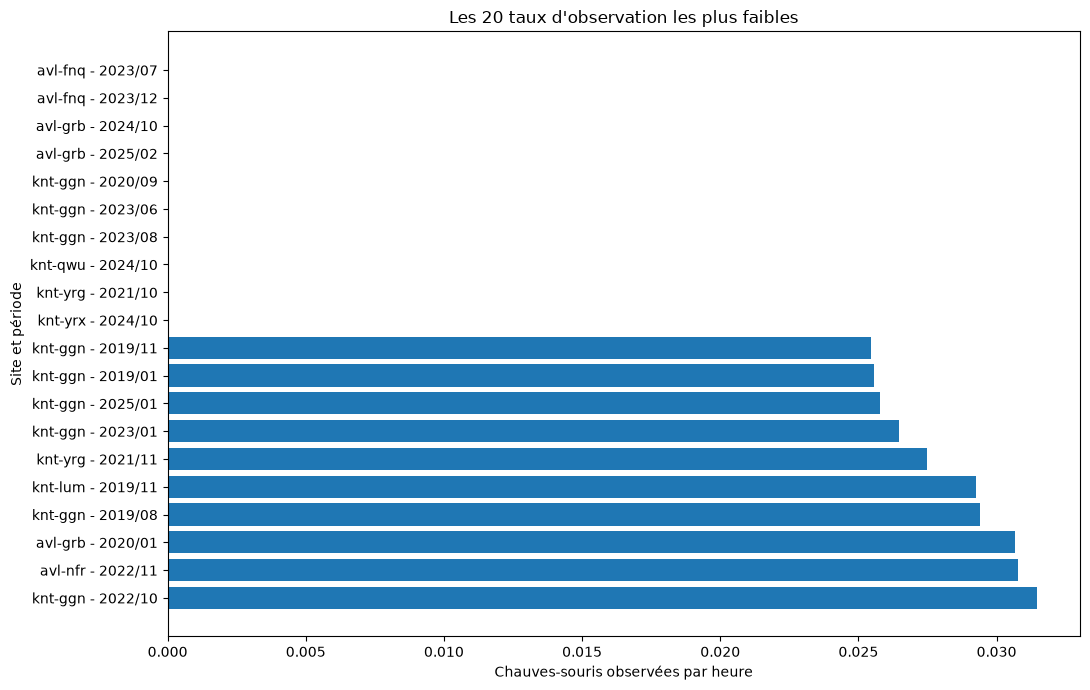

In [151]:
import matplotlib.pyplot as plt

# Sélectionner les 20 taux les plus faibles
lowest = g_month.nsmallest(20, 'weighted_rate').copy()

# Identifier chaque site et période
lowest['periode'] = (
    lowest['site_code']
    + ' - '
    + lowest['year'].astype(str)
    + '/'
    + lowest['month'].astype(str).str.zfill(2)
)

# Afficher les résultats
plt.figure(figsize=(11, 7))

plt.barh(lowest['periode'], lowest['weighted_rate'])

plt.xlabel('Chauves-souris observées par heure')
plt.ylabel('Site et période')
plt.title("Les 20 taux d'observation les plus faibles")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plusieurs sites présentent des taux d'observation très faibles, voire nuls, notamment KNT-GGN et AVL-FNQ. Le site KNT-GGN apparaît plusieurs fois parmi les 20 taux les plus faibles,Mais ces faibles taux ne constituent pas forcément des anomalies : ils peuvent aussi s'expliquer par des variations saisonnières ou des conditions d'observation différentes.

Activité mensuelle globale


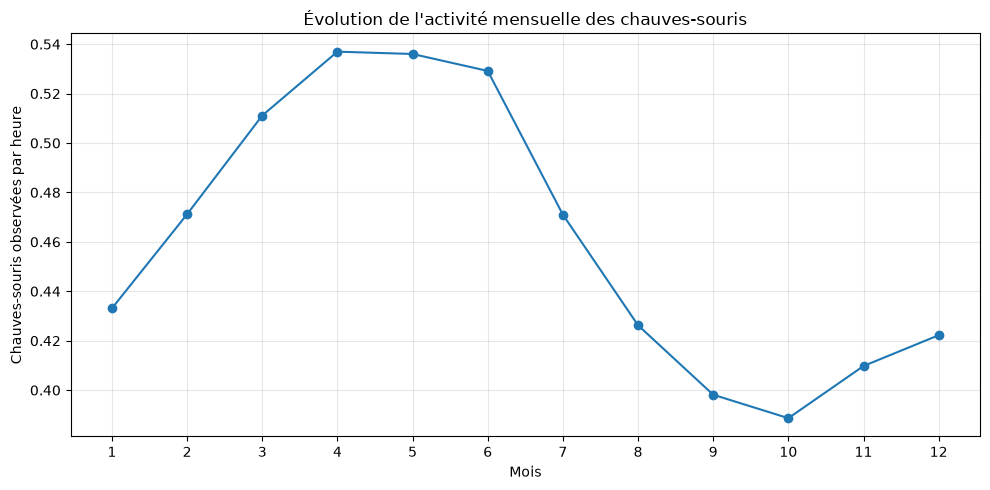

In [152]:
# Visualiser l'activité mensuelle globale
plt.figure(figsize=(10, 5))

plt.plot(
    activite_mensuelle.index,
    activite_mensuelle['rate'],
    marker='o'
)

plt.xticks(range(1, 13))
plt.xlabel('Mois')
plt.ylabel('Chauves-souris observées par heure')
plt.title("Évolution de l'activité mensuelle des chauves-souris")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

On remarque que l'activité des chauves-souris varie selon les mois. Elle augmente progressivement de janvier à avril, où elle atteint son maximum (environ 0,54 chauve-souris par heure), puis diminue à partir de juillet pour atteindre son minimum en octobre (environ 0,39).

Activité normalisée par heure

,bats_per_hour,detections_per_hour
count,4992.000000,4992.000000
mean,0.466249,0.673006
std,0.259228,0.376138
min,0.000000,0.000000
25%,0.290323,0.415546
50%,0.424837,0.610465
75%,0.596026,0.853659
max,2.417219,3.085714


Sites avec la plus faible activité observée  :


,n_enquetes,heures,chauves_souris,detections,bats_per_hour,detections_per_hour
site_code,,,,,,
knt-ggn,78,2408.7,237,353,0.098393,0.146552
knt-yrg,78,2221.3,468,622,0.210687,0.280016
knt-gkr,78,2452.2,532,725,0.216948,0.295653
avl-grb,78,2376.4,546,849,0.229759,0.357263
avl-nfr,78,2392.9,550,816,0.229847,0.341009
avl-fnq,78,2212.4,521,687,0.235491,0.310523
tmb-dlq,78,2360.1,559,763,0.236854,0.323291
tmb-uvf,78,2404.7,661,952,0.274878,0.395891
avl-aru,78,2483.9,726,1087,0.292282,0.437618


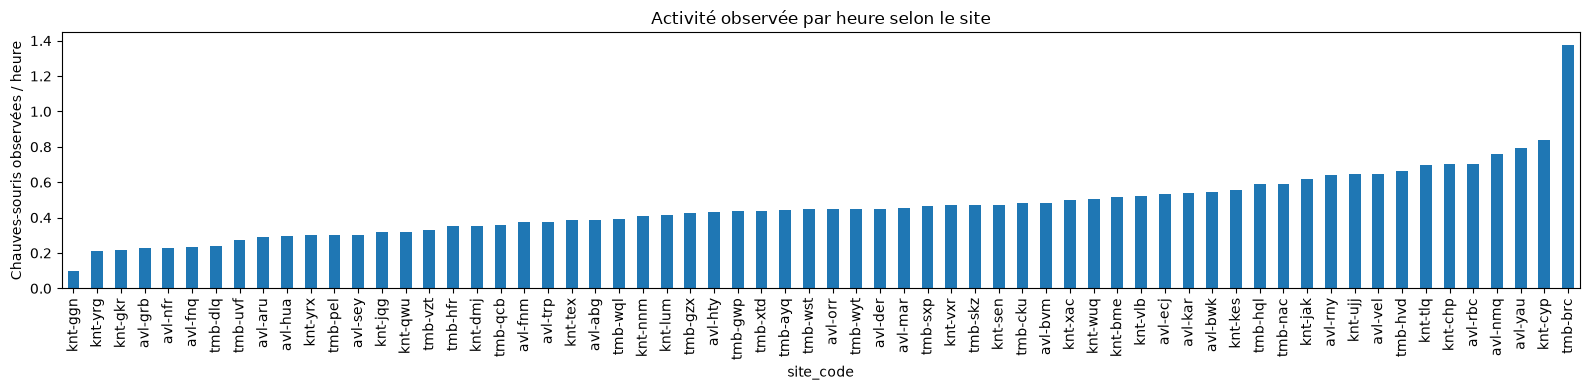

In [153]:
df["bats_per_hour"] = df["observed_bat_count"] / df["observation_hours"].replace(0,np.nan)
df["detections_per_hour"] = df["acoustic_detection_count"] / df["observation_hours"].replace(0,np.nan)
display(df[["bats_per_hour","detections_per_hour"]].describe())
site = df.groupby("site_code").agg(n_enquetes=("survey_id","count"),heures=("observation_hours","sum"),chauves_souris=("observed_bat_count","sum"),detections=("acoustic_detection_count","sum"))
site["bats_per_hour"] = site.chauves_souris/site.heures.replace(0,np.nan)
site["detections_per_hour"] = site.detections/site.heures.replace(0,np.nan)
print("Sites avec la plus faible activité observée  :")
display(site.sort_values("bats_per_hour").head(15))
site.bats_per_hour.sort_values().plot(kind="bar",figsize=(16,4),title="Activité observée par heure selon le site")
plt.ylabel("Chauves-souris observées / heure");plt.tight_layout();plt.show()

Corrélations et précautions

## Détection d’anomalies

In [154]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
features=["bats_per_hour","detections_per_hour","nightly_visit_count","weather_interference","comparison_species_count"]
X=df[features].replace([np.inf,-np.inf],np.nan)
valid=X.notna().all(axis=1)
Xscaled=StandardScaler().fit_transform(X.loc[valid])
model=IsolationForest(n_estimators=300,contamination=0.03,random_state=42)
df["anomaly_score"]=np.nan;df["anomaly"] = pd.NA
df.loc[valid,"anomaly_score"]=model.fit(Xscaled).score_samples(Xscaled)
df.loc[valid,"anomaly"]=model.predict(Xscaled)
anomalies=df.loc[df["anomaly"]==-1].sort_values("anomaly_score")
print("Anomalies :",len(anomalies),"sur",valid.sum(),"observations exploitables")
print("Sites avec le plus d'anomalies :")
display(anomalies.groupby("site_code").size().sort_values(ascending=False).head(20).rename("nb_anomalies").to_frame())


Anomalies : 150 sur 4992 observations exploitables
Sites avec le plus d'anomalies :


,nb_anomalies
site_code,
tmb-brc,69
knt-cyp,14
avl-yau,10
avl-rbc,7
knt-chp,6
avl-nmq,5
tmb-hfr,5
avl-fnq,4
avl-rny,4


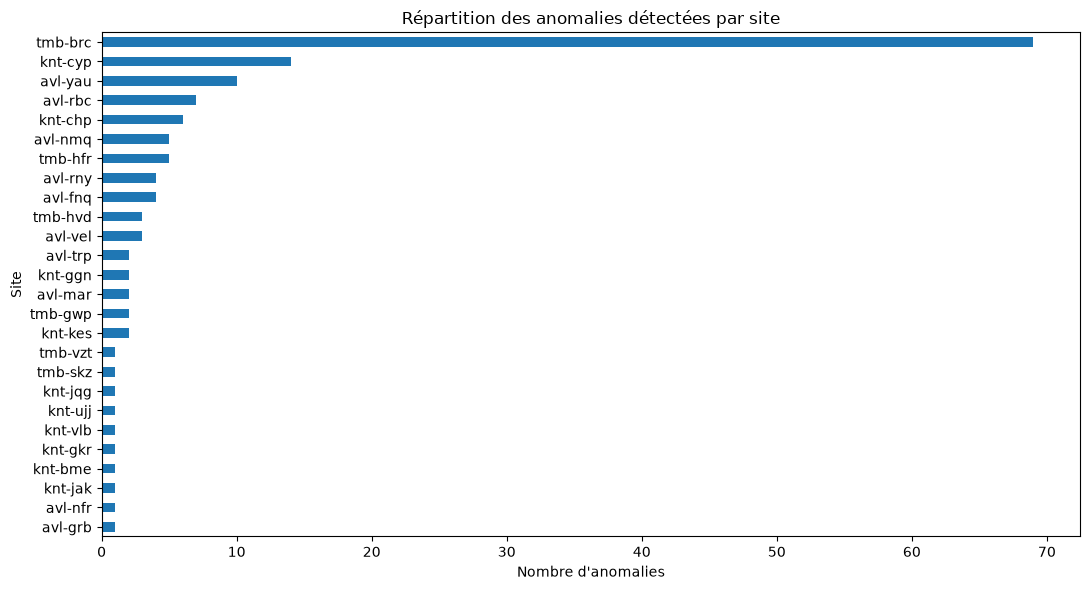

In [155]:
# Nombre d'anomalies détectées par site
anomalies_site = anomalies.groupby('site_code').size().sort_values()

plt.figure(figsize=(11, 6))
anomalies_site.plot(kind='barh')

plt.xlabel("Nombre d'anomalies")
plt.ylabel("Site")
plt.title("Répartition des anomalies détectées par site")
plt.tight_layout()
plt.show()

Examiner les anomalies du site TMB-BRC


In [156]:
# Examiner les anomalies du site TMB-BRC
anomalies_brc = anomalies[
    anomalies['site_code'] == 'tmb-brc'
]

display(anomalies_brc[
    ['survey_id', 'survey_start', 'anomaly_score'] + features
].head(15))

,survey_id,survey_start,anomaly_score,bats_per_hour,detections_per_hour,nightly_visit_count,weather_interference,comparison_species_count
4042,BAT-0004043,2024-05-05 18:00:00,-0.751834,1.885246,2.732240,42,16.9,15
3995,BAT-0003996,2020-06-05 18:00:00,-0.736488,1.926346,2.832861,39,25.3,14
4005,BAT-0004006,2021-04-05 18:00:00,-0.735016,2.050562,2.500000,45,35.0,13
4019,BAT-0004020,2022-06-05 18:00:00,-0.734653,1.700880,2.815249,43,31.0,13
4051,BAT-0004052,2025-02-05 18:00:00,-0.732029,2.417219,2.549669,54,39.1,8
4032,BAT-0004033,2023-07-05 18:00:00,-0.726325,1.333333,2.070175,40,24.4,20
3999,BAT-0004000,2020-10-05 18:00:00,-0.725751,1.639785,2.715054,42,22.3,7
4008,BAT-0004009,2021-07-05 18:00:00,-0.724457,1.373626,2.445055,39,19.0,16
3988,BAT-0003989,2019-11-05 18:00:00,-0.723266,1.596639,2.352941,33,61.8,17
4030,BAT-0004031,2023-05-05 18:00:00,-0.722421,1.468750,2.343750,35,37.2,19


In [157]:
# Comparer les anomalies de TMB-BRC aux observations normales
comparaison = df.assign(
    groupe=np.where(
        df["anomaly"] == -1,
        "Anomalie",
        "Normal"
    )
)

comparaison = comparaison[
    (comparaison["site_code"] == "tmb-brc")
    & comparaison["anomaly"].notna()
]

display(
    comparaison.groupby("groupe")[features]
    .median()
    .round(2)
)

,bats_per_hour,detections_per_hour,nightly_visit_count,weather_interference,comparison_species_count
groupe,,,,,
Anomalie,1.42,2.06,31.0,40.4,12.0
Normal,0.87,1.32,19.0,37.4,12.0


Pour comprendre ces anomalies, nous avons comparé les valeurs médianes des observations atypiques et normales du site.

Les observations atypiques présentent des taux d'observation de chauves-souris et de détection acoustique environ 60 % plus élevés, ainsi qu'un nombre de visites nocturnes plus important.

Ces résultats suggèrent que les anomalies sont principalement liées à une activité particulièrement élevée sur ce site.

## Distances et clustering
StandardScaler et KMeans pour interpréter les profils

In [158]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
Xs=StandardScaler().fit_transform(X.loc[valid]); scores={}
for k in range(2,7):
 labels=KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(Xs)
 scores[k]=silhouette_score(Xs,labels,sample_size=min(2000,len(Xs)),random_state=42)
print("Scores silhouette :",scores)
k=max(scores,key=scores.get)
df["cluster"] = pd.NA
df.loc[valid,"cluster"]=KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(Xs)
print("Nombre de groupes retenu pour l'exploration :",k)
display(df.loc[valid].groupby("cluster")[features].agg(["mean","median"]).round(2))
display(df.loc[valid].groupby("cluster").size().rename("effectif"))

Scores silhouette : {2: 0.29155282799645554, 3: 0.1976582688399502, 4: 0.1934082792841612, 5: 0.19841861970597757, 6: 0.19475013315797443}
Nombre de groupes retenu pour l'exploration : 2


bats_per_hour        detections_per_hour        nightly_visit_count  \
                 mean median                mean median                mean   
cluster                                                                       
0                0.36   0.35                0.51   0.51                7.51   
1                0.74   0.69                1.09   1.02               16.59   

               weather_interference        comparison_species_count         
        median                 mean median                     mean median  
cluster                                                                     
0          7.0                39.38  39.00                    10.50   10.0  
1         16.0                32.76  32.05                    11.26   11.0

cluster
0    3564
1    1428
Name: effectif, dtype: int64

Le premier groupe correspond à une activité relativement faible, tandis que le second présente des taux d'observation et de détection acoustique environ deux fois plus élevés, ainsi qu'un nombre plus important de visites nocturnes.

Les deux groupes se distinguent donc principalement par l'intensité de l'activité observée.

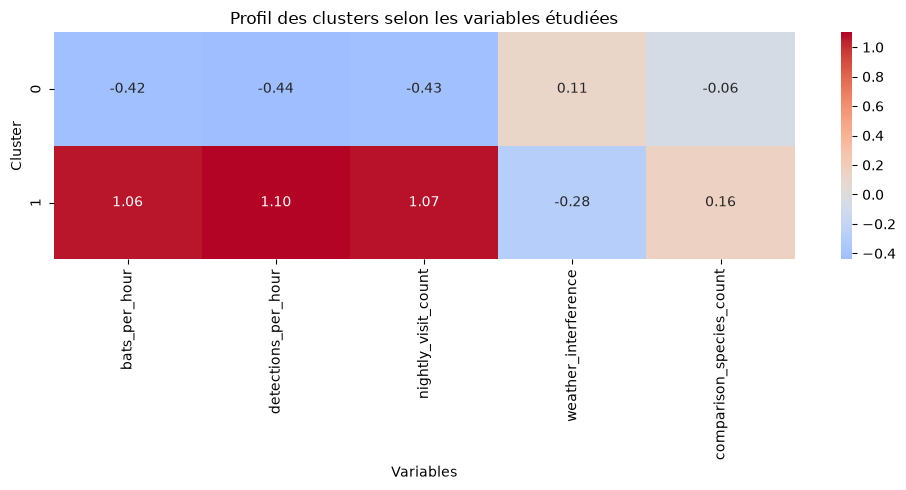

In [159]:
# Moyennes des variables pour chaque cluster
profils = df.loc[valid].groupby('cluster')[features].mean()

# Standardiser pour comparer des variables d'échelles différentes
profils_normalises = (
    profils - df.loc[valid, features].mean()
) / df.loc[valid, features].std().replace(0, np.nan)

plt.figure(figsize=(10, 5))

sns.heatmap(
    profils_normalises,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Profil des clusters selon les variables étudiées")
plt.xlabel("Variables")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## Investigation de KNT-KES : rupture d'activité

Dans cette partie, nous cherchons à examiner une éventuelle rupture d'activité des chauves-souris sur le site KNT-KES en 2024.

Pour cela, nous comparons les observations réalisées sur ce site à différentes périodes, en utilisant le nombre de chauves-souris observées par heure afin de tenir compte des différences de durée des relevés.

Nous étudions d'abord l'activité du mois de mai sur plusieurs années, puis nous comparons cette évolution à celle des autres sites. Enfin, nous examinons les mois précédant et suivant mai 2024 afin de déterminer si cette baisse est ponctuelle ou s'inscrit dans une évolution plus progressive.

### Taux d'activité


In [ ]:
df["bats_per_hour"] = (
    df["observed_bat_count"]
    / df["observation_hours"].replace(0, np.nan)
)

df["survey_start"] = pd.to_datetime(df["survey_start"])

kes = df[df["site_code"].str.lower() == "knt-kes"].copy()

kes["annee"] = kes["survey_start"].dt.year
kes["mois"] = kes["survey_start"].dt.month

# Comparaison de tous les mois de mai
mai = kes[kes["mois"] == 5].sort_values("annee")

display(
    mai[[
        "survey_id",
        "annee",
        "observed_bat_count",
        "bats_per_hour",
        "acoustic_detection_count",
        "colony_estimate",
        "survey_quality"
    ]]
)

,survey_id,annee,observed_bat_count,bats_per_hour,acoustic_detection_count,colony_estimate,survey_quality
4,BAT-0000005,2019,23,0.718750,29,20.9,acceptable
16,BAT-0000017,2020,32,0.943953,31,25.3,high
28,BAT-0000029,2021,11,0.336391,18,9.8,acceptable
40,BAT-0000041,2022,25,0.726744,28,30.9,acceptable
52,BAT-0000053,2023,17,0.677291,34,17.7,acceptable
64,BAT-0000065,2024,3,0.110701,12,5.7,acceptable
76,BAT-0000077,2025,23,0.766667,39,26.8,high


La comparaison des relevés du mois de mai entre 2019 et 2025 met en évidence une forte diminution de l'activité en 2024 sur le site KNT-KES.

Seulement 3 chauves-souris ont été observées, avec un taux de 0,111 chauve-souris par heure, soit la valeur la plus faible de la période étudiée. L'estimation de la colonie atteint également son minimum (5,7).

En 2025, le taux d'activité remonte à 0,767, ce qui suggère que la diminution observée en 2024 n'a pas persisté au même niveau.

### Comparer 2024 à la moyenne des autres années


Pour déterminer si la diminution observée à KNT-KES est particulière à ce site, on va comparer le taux d'activité de mai 2024 à la moyenne des mois de mai des autres années pour chaque site.

In [161]:
df["annee"] = df["survey_start"].dt.year
df["mois"] = df["survey_start"].dt.month

mai_tous = df[df["mois"] == 5].copy()

comparaison = (
    mai_tous.groupby(["site_code", "annee"])["bats_per_hour"]
    .mean()
    .unstack()
)

# Comparer 2024 à la moyenne des autres années
autres_annees = comparaison.drop(
    columns=2024, errors="ignore"
)

comparaison["moyenne_autres_annees"] = (
    autres_annees.mean(axis=1)
)

comparaison["variation_2024_pct"] = (
    (
        comparaison[2024]
        / comparaison["moyenne_autres_annees"]
    ) - 1
) * 100

display(
    comparaison[
        [2024, "moyenne_autres_annees", "variation_2024_pct"]
    ].sort_values("variation_2024_pct")
)

annee,2024,moyenne_autres_annees,variation_2024_pct
site_code,,,
knt-kes,0.110701,0.694966,-84.071004
avl-nfr,0.085106,0.352033,-75.824346
avl-fnm,0.176056,0.447526,-60.660121
knt-gkr,0.202532,0.378721,-46.522262
avl-aru,0.275482,0.505461,-45.498893
...,...,...,...
avl-nmq,1.111111,0.671605,65.441161
avl-trp,0.561056,0.338095,65.946116
tmb-wql,0.562130,0.332219,69.204612


KNT-KES présente la plus forte baisse, avec une diminution de 84,1 %.

D'autres sites présentent également des baisses importantes, notamment AVL-NFR (-75,8 %) et AVL-FNM (-60,7 %).

Cette comparaison confirme que KNT-KES se distingue particulièrement en mai 2024, mais montre également que la diminution de l'activité ne concerne pas uniquement ce site.

In [162]:
periode = kes[
    (kes["survey_start"] >= "2023-10-01")
    & (kes["survey_start"] <= "2024-09-30")
].sort_values("survey_start")

display(
    periode[[
        "survey_id",
        "survey_start",
        "observed_bat_count",
        "bats_per_hour",
        "acoustic_detection_count",
        "colony_estimate",
        "survey_quality"
    ]]
)

,survey_id,survey_start,observed_bat_count,bats_per_hour,acoustic_detection_count,colony_estimate,survey_quality
57,BAT-0000058,2023-10-05 18:00:00,11,0.364238,15,16.3,high
58,BAT-0000059,2023-11-05 18:00:00,23,0.653409,28,29.5,acceptable
59,BAT-0000060,2023-12-05 18:00:00,8,0.237389,17,9.6,high
60,BAT-0000061,2024-01-05 18:00:00,17,0.544872,38,17.7,high
61,BAT-0000062,2024-02-05 18:00:00,21,0.668790,37,24.8,high
62,BAT-0000063,2024-03-05 18:00:00,16,0.501567,30,18.5,acceptable
63,BAT-0000064,2024-04-05 18:00:00,10,0.334448,15,9.5,acceptable
64,BAT-0000065,2024-05-05 18:00:00,3,0.110701,12,5.7,acceptable
65,BAT-0000066,2024-06-05 18:00:00,14,0.489510,7,15.8,acceptable
66,BAT-0000067,2024-07-05 18:00:00,11,0.366667,9,10.1,high


### Les 10 sites avec les plus fortes baisses


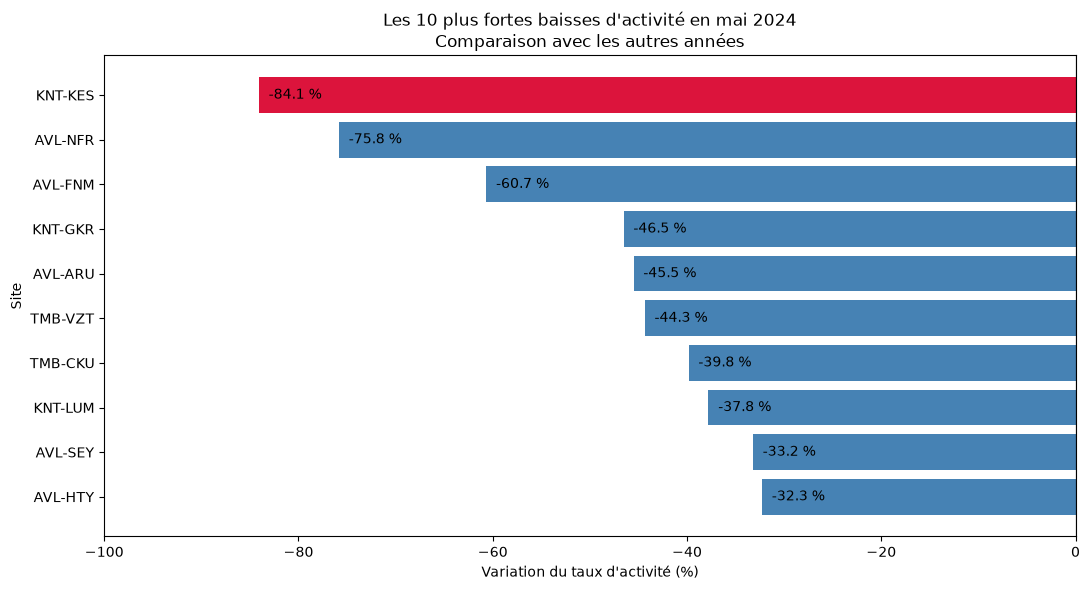

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

# Les 10 sites avec les plus fortes baisses
top10 = (
    comparaison["variation_2024_pct"]
    .dropna()
    .nsmallest(10)
    .sort_values()
)

# Graphique
plt.figure(figsize=(11, 6))

couleurs = [
    "crimson" if site == "knt-kes" else "steelblue"
    for site in top10.index
]

barres = plt.barh(
    top10.index.str.upper(),
    top10.values,
    color=couleurs
)

plt.gca().invert_yaxis()

# Afficher les pourcentages
for barre, valeur in zip(barres, top10.values):
    plt.text(
        valeur + 1,
        barre.get_y() + barre.get_height() / 2,
        f"{valeur:.1f} %",
        va="center",
        fontsize=10
    )

plt.xlim(-100, 0)
plt.xlabel("Variation du taux d'activité (%)")
plt.ylabel("Site")
plt.title(
    "Les 10 plus fortes baisses d'activité en mai 2024\n"
    "Comparaison avec les autres années"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

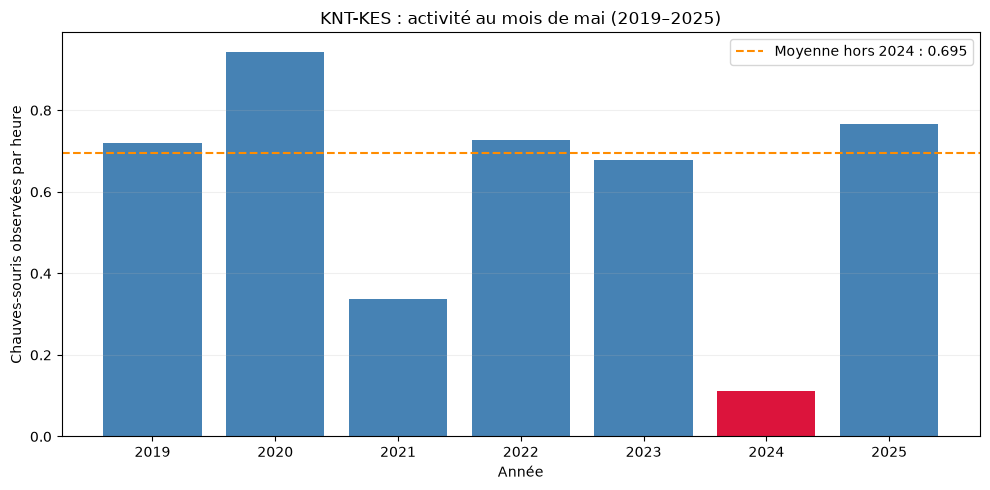

In [164]:
plt.figure(figsize=(10, 5))

couleurs = [
    "crimson" if annee == 2024 else "steelblue"
    for annee in mai["annee"]
]

plt.bar(
    mai["annee"].astype(str),
    mai["bats_per_hour"],
    color=couleurs
)

# Moyenne des autres années
moyenne = mai.loc[
    mai["annee"] != 2024, "bats_per_hour"
].mean()

plt.axhline(
    moyenne,
    color="darkorange",
    linestyle="--",
    label=f"Moyenne hors 2024 : {moyenne:.3f}"
)

plt.xlabel("Année")
plt.ylabel("Chauves-souris observées par heure")
plt.title("KNT-KES : activité au mois de mai (2019–2025)")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

On remarque une forte baisse de l'activité à KNT-KES en mai 2024, avec seulement 0,111 chauve-souris observée par heure, contre une moyenne de 0,695 pour les autres années, soit une diminution de 84 %.

Même en 2021, où l'activité était déjà assez faible, le taux restait trois fois plus élevé. En 2025, il remonte à 0,767.

Mai 2024 se distingue donc clairement des autres années. Il reste à comprendre ce qui pourrait expliquer cette baisse.

In [166]:
# Comparer avril 2024 aux autres mois d'avril
avril = kes[kes["mois"] == 4].copy()

comparaison_avril = (
    avril.groupby("annee")
    .agg(
        nb_releves=("survey_id", "count"),
        chauves_souris=("observed_bat_count", "sum"),
        heures=("observation_hours", "sum")
    )
)

comparaison_avril["taux_activite"] = (
    comparaison_avril["chauves_souris"]
    / comparaison_avril["heures"].replace(0, np.nan)
)

display(comparaison_avril)

# Comparaison avec les années autres que 2024
reference = comparaison_avril.loc[
    comparaison_avril.index != 2024
]

taux_reference = (
    reference["chauves_souris"].sum()
    / reference["heures"].sum()
)

taux_2024 = comparaison_avril.loc[2024, "taux_activite"]

variation = (taux_2024 / taux_reference - 1) * 100

print(f"Taux avril 2024 : {taux_2024:.3f}")
print(f"Taux de référence : {taux_reference:.3f}")
print(f"Variation : {variation:.1f} %")

,nb_releves,chauves_souris,heures,taux_activite
annee,,,,
2019,1,26,35.7,0.728291
2020,1,28,27.3,1.025641
2021,1,9,37.2,0.241935
2022,1,40,39.3,1.017812
2023,1,22,31.3,0.702875
2024,1,10,29.9,0.334448
2025,1,21,27.6,0.760870


Taux avril 2024 : 0.334
Taux de référence : 0.736
Variation : -54.6 %


# Bilan
Les analyses mettent en évidence une situation particulièrement suspecte sur le site KNT-KES en mai 2024.

Une chute de 84 % de l'activité en mai 2024, soit la plus forte baisse parmi les sites étudiés.

Une diminution déjà visible en avril 2024 (-55 %), ce qui laisse penser que le phénomène aurait pu commencer avant mai.

Une estimation de la colonie particulièrement faible en mai 2024 (5,7 contre 17,7 en 2023 et 26,8 en 2025).

Une remontée de l'activité après mai 2024, avec un retour à un niveau habituel en mai 2025.

Ces observations nous amènent à suspecter une perturbation temporaire sur le site KNT-KES au printemps 2024, qui aurait pu affecter l'activité des chauves-souris.

Le fait que d'autres sites présentent également des baisses importantes en mai 2024 soulève une deuxième hypothèse : un phénomène environnemental plus large aurait pu toucher plusieurs sites.